In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv('ckd-dataset-v2.csv')
data = data.drop([0,1]).reset_index(drop=True)
data.head(3)

,bp (Diastolic),bp limit,sg,al,class,rbc,su,pc,pcc,ba,...,htn,dm,cad,appet,pe,ane,grf,stage,affected,age
0,0,0,1.019 - 1.021,1 - 1,ckd,0,< 0,0,0,0,...,0,0,0,0,0,0,≥ 227.944,s1,1,< 12
1,0,0,1.009 - 1.011,< 0,ckd,0,< 0,0,0,0,...,0,0,0,0,0,0,≥ 227.944,s1,1,< 12
2,0,0,1.009 - 1.011,≥ 4,ckd,1,< 0,1,0,1,...,0,0,0,1,0,0,127.281 - 152.446,s1,1,< 12


In [3]:
data = data[data['grf'] != ' p ']
data['grf'].unique()

<StringArray>
[        '≥ 227.944', '127.281 - 152.446', '102.115 - 127.281',
 '177.612 - 202.778', '26.6175 - 51.7832',  '51.7832 - 76.949',
  '76.949 - 102.115', '152.446 - 177.612', '202.778 - 227.944',
         '< 26.6175']
Length: 10, dtype: str

In [4]:
bgr_mapping = {
    '< 112': 0,
    '112 - 154': 1,
    '154 - 196': 2,
    '196 - 238': 3,
    '238 - 280': 4,
    '280 - 322': 5,
    '322 - 364': 6,
    '364 - 406': 7,
    '406 - 448': 8,
    '≥ 448': 9
}

bu_mapping = {
    '< 48.1': 0,
    '48.1 - 86.2': 1,
    '86.2 - 124.3': 2,
    '124.3 - 162.4': 3,
    '162.4 - 200.5': 4,
    '200.5 - 238.6': 5,
    '238.6 - 276.7': 6,
    '≥ 352.9': 7
}

sod_mapping = {
    '< 118': 0,
    '118 - 123': 1,
    '123 - 128': 2,
    '128 - 133': 3,
    '133 - 138': 4,
    '138 - 143': 5,
    '143 - 148': 6,
    '148 - 153': 7,
    '≥ 158': 8
}
# Mapping the 9 original codes into the 4 clinical tiers
four_level_mapping = {
    '< 118': 1,      # Maps to Group 1 (Lowest Sodium, HR 1.45 prior)
    '118 - 123': 1,  # Maps to Group 1 (Lowest Sodium, HR 1.45 prior)
    '123 - 128': 1,  # Maps to Group 1 (Lowest Sodium, HR 1.45 prior)
    '128 - 133': 1,  # Maps to Group 1 (Lowest Sodium, HR 1.45 prior)
    '133 - 138': 2,  # Maps to Group 2 (Reference group, no prior)
    '138 - 143': 3,  # Maps to Group 3 (High-normal, HR 1.18 prior)
    '143 - 148': 4,  # Maps to Group 4 (Hypernatremia, HR 1.22 prior)
    '148 - 153': 4,  # Maps to Group 4 (Hypernatremia, HR 1.22 prior)
    '≥ 158': 4       # Maps to Group 4 (Hypernatremia, HR 1.22 prior)
}

# Apply this directly to your dataframe column:
# df['sod_clinical_tier'] = df['sod_column'].map(four_level_mapping)

# Example of applying it to your dataframe
# df['sod_4_levels'] = df['sod_original_code'].map(four_level_mapping)

sc_mapping = {
    '< 3.65': 0,
    '3.65 - 6.8': 1,
    '6.8 - 9.95': 2,
    '9.95 - 13.1': 3,
    '13.1 - 16.25': 4,
    '16.25 - 19.4': 5,
    '≥ 28.85': 6
}

pot_mapping = {
    '< 7.31': 0,
    '7.31 - 11.72': 1,
    '38.18 - 42.59': 2,
    '≥ 42.59': 3
}

hemo_mapping = {
    '< 6.1': 0,
    '6.1 - 7.4': 1,
    '7.4 - 8.7': 2,
    '8.7 - 10': 3,
    '10 - 11.3': 4,
    '11.3 - 12.6': 5,
    '12.6 - 13.9': 6,
    '13.9 - 15.2': 7,
    '15.2 - 16.5': 8,
    '≥ 16.5': 9
}

pcv_mapping = {
    '< 17.9': 0,
    '17.9 - 21.8': 1,
    '21.8 - 25.7': 2,
    '25.7 - 29.6': 3,
    '29.6 - 33.5': 4,
    '33.5 - 37.4': 5,
    '37.4 - 41.3': 6,
    '41.3 - 45.2': 7,
    '45.2 - 49.1': 8,
    '≥ 49.1': 9
}

rbcc_mapping = {
    '< 2.69': 0,
    '2.69 - 3.28': 1,
    '3.28 - 3.87': 2,
    '3.87 - 4.46': 3,
    '4.46 - 5.05': 4,
    '5.05 - 5.64': 5,
    '5.64 - 6.23': 6,
    '6.23 - 6.82': 7,
    '≥ 7.41': 8
}

wbcc_mapping = {
    '< 4980': 0,
    '4980 - 7360': 1,
    '7360 - 9740': 2,
    '9740 - 12120': 3,
    '12120 - 14500': 4,
    '14500 - 16880': 5,
    '16880 - 19260': 6,
    '19260 - 21640': 7,
    '≥ 24020': 8
}

age_mapping = {
    '< 12': 0,
    '12 - 20': 1,
    '20 - 27': 2,
    '27 - 35': 3,
    '35 - 43': 4,
    '43 - 51': 5,
    '51 - 59': 6,
    '59 - 66': 7,
    '66 - 74': 8,
    '≥ 74': 9
}

data['bgr'] = data['bgr'].map(bgr_mapping)
data['bu'] = data['bu'].map(bu_mapping)
data['sod'] = data['sod'].map(four_level_mapping)
data['sc'] = data['sc'].map(sc_mapping)
data['pot'] = data['pot'].map(pot_mapping)
data['hemo'] = data['hemo'].map(hemo_mapping)
data['pcv'] = data['pcv'].map(pcv_mapping)
data['rbcc'] = data['rbcc'].map(rbcc_mapping)
data['wbcc'] = data['wbcc'].map(wbcc_mapping)
data['age'] = data['age'].map(age_mapping)

sg_mapping = {
    '< 1.007': 0,
    '1.009 - 1.011': 1,
    '1.015 - 1.017': 2,
    '1.019 - 1.021': 3,
    '≥ 1.023': 4
}
al_mapping = {
    '< 0': 0,
    '1 - 1': 1,
    '2 - 2': 2,
    '3 - 3': 3,
    '≥ 4': 4
}
su_mapping = {
    '< 0': 0,
    '1 - 2': 1,
    '2 - 2': 2,
    '3 - 4': 3,
    '4 - 4': 4,
    '≥ 4': 5
}
grf_mapping = {
    '< 26.6175': 0,
    '26.6175 - 51.7832': 1,
    '51.7832 - 76.949': 2,
    '76.949 - 102.115': 3,
    '102.115 - 127.281': 4,
    '127.281 - 152.446': 5,
    '152.446 - 177.612': 6,
    '177.612 - 202.778': 7,
    '202.778 - 227.944': 8,
    '≥ 227.944': 9
}
stage_mapping = {
    's1': 0,
    's2': 1,
    's3': 2,
    's4': 3,
    's5': 4
}
class_mapping = {
    'notckd': 0,
    'ckd': 1
}
# Apply mappings
data['sg'] = data['sg'].map(sg_mapping)
data['al'] = data['al'].map(al_mapping)
data['su'] = data['su'].map(su_mapping)
data['grf'] = data['grf'].map(grf_mapping)
data['stage'] = data['stage'].map(stage_mapping)
data['class'] = data['class'].map(class_mapping)

In [5]:
data['bp (Diastolic)'] = data['bp (Diastolic)'].astype(int)
data['bp limit'] = data['bp limit'].astype(int)
data['rbc'] = data['rbc'].astype(int)
data['pc'] = data['pc'].astype(int)
data['pcc'] = data['pcc'].astype(int)
data['ba'] = data['ba'].astype(int)
data['htn'] = data['htn'].astype(int)
data['dm'] = data['dm'].astype(int)
data['cad'] = data['cad'].astype(int)
data['appet'] = data['appet'].astype(int)
data['pe'] = data['pe'].astype(int)
data['ane'] = data['ane'].astype(int)
data['affected'] = data['affected'].astype(int)

In [6]:
print(data.dtypes)

bp (Diastolic)    int64
bp limit          int64
sg                int64
al                int64
class             int64
rbc               int64
su                int64
pc                int64
pcc               int64
ba                int64
bgr               int64
bu                int64
sod               int64
sc                int64
pot               int64
hemo              int64
pcv               int64
rbcc              int64
wbcc              int64
htn               int64
dm                int64
cad               int64
appet             int64
pe                int64
ane               int64
grf               int64
stage             int64
affected          int64
age               int64
dtype: object


In [7]:
duplicate_pairs = [
    (data.columns[i], data.columns[j])
    for i in range(len(data.columns))
    for j in range(i)
    if data.iloc[:, i].equals(data.iloc[:, j])
]
print(duplicate_pairs)

[('affected', 'class')]


In [8]:
df = data.drop(columns=['affected'])

In [9]:
for col in df.columns:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False).sort_index())
    print()

--- bp (Diastolic) ---
bp (Diastolic)
0     92
1    107
Name: count, dtype: int64

--- bp limit ---
bp limit
0    95
1    59
2    45
Name: count, dtype: int64

--- sg ---
sg
0     3
1    45
2    36
3    74
4    41
Name: count, dtype: int64

--- al ---
al
0    115
1     21
2     27
3     23
4     13
Name: count, dtype: int64

--- class ---
class
0     72
1    127
Name: count, dtype: int64

--- rbc ---
rbc
0    174
1     25
Name: count, dtype: int64

--- su ---
su
0    169
1      6
2      9
3      8
4      6
5      1
Name: count, dtype: int64

--- pc ---
pc
0    154
1     45
Name: count, dtype: int64

--- pcc ---
pcc
0    172
1     27
Name: count, dtype: int64

--- ba ---
ba
0    188
1     11
Name: count, dtype: int64

--- bgr ---
bgr
0    69
1    79
2    13
3    14
4    11
5     4
6     1
7     1
8     4
9     3
Name: count, dtype: int64

--- bu ---
bu
0    108
1     53
2     16
3     10
4      5
5      5
6      1
7      1
Name: count, dtype: int64

--- sod ---
sod
1    27
2    91
3    

<Axes: >

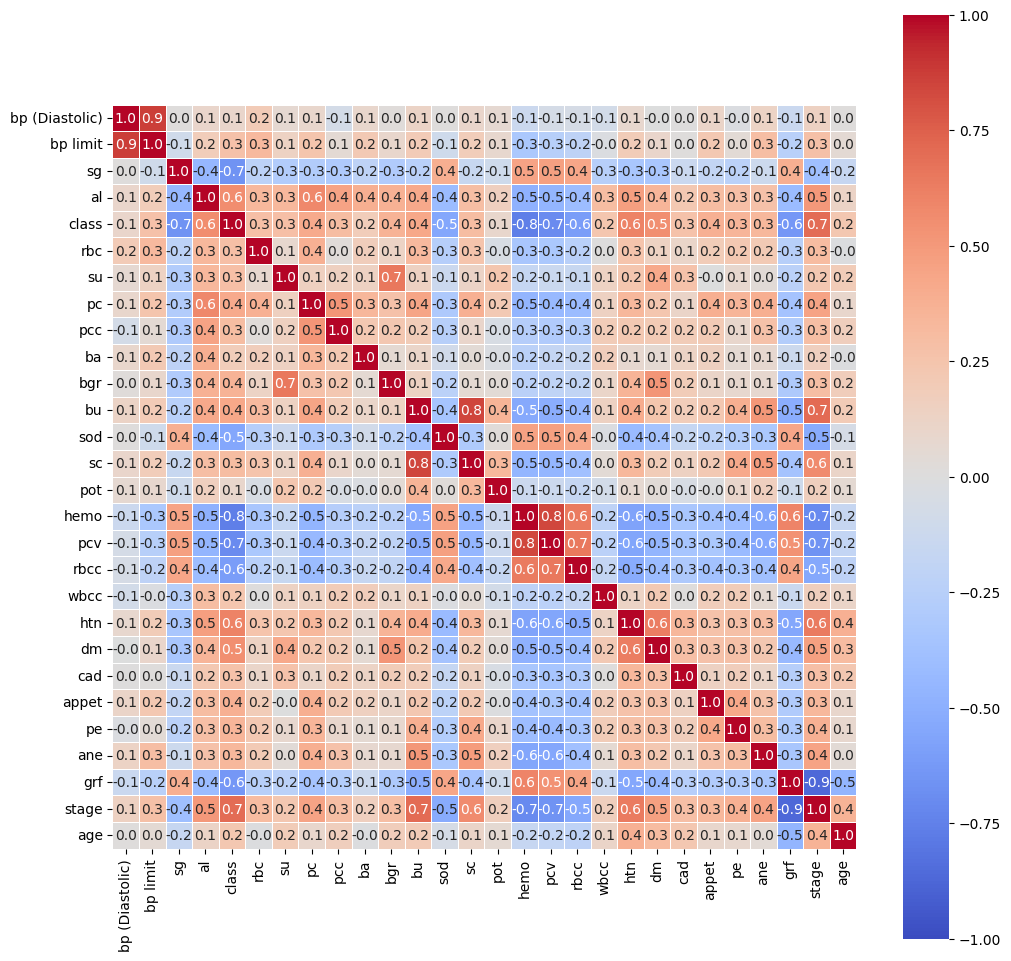

In [10]:
import seaborn as sns
corr_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(12, 12))

sns.heatmap(
    corr_matrix, 
    annot=True,          # Overlays the actual correlation numbers on the cells
    cmap='coolwarm',     # Diverging colormap (blue = negative, red = positive)
    vmin=-1, vmax=1,     # Anchors the colorbar scale from -1 to 1
    fmt=".1f",           # Limits annotations to 2 decimal places
    linewidths=0.5,      # Adds subtle gridlines between cells
    square=True          # Forces cells to be perfectly square shapes
)

In [11]:
stage_corr = corr_matrix['stage'].drop('stage').sort_values(key=abs, ascending=False)
print(stage_corr)

grf              -0.868790
bu                0.709443
hemo             -0.706493
class             0.700282
pcv              -0.661322
htn               0.637410
sc                0.567245
rbcc             -0.546456
sod              -0.528115
al                0.507441
dm                0.463952
pc                0.449010
ane               0.446358
sg               -0.394240
pe                0.380725
age               0.364278
appet             0.333919
rbc               0.307955
pcc               0.291054
bgr               0.290701
cad               0.287741
bp limit          0.280470
su                0.228269
pot               0.167898
wbcc              0.164788
ba                0.159912
bp (Diastolic)    0.145311
Name: stage, dtype: float64


In [12]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

X_check = df.drop(columns=['stage', 'grf']).select_dtypes(include='number')
X_check = add_constant(X_check)  # VIF calc needs a constant term

vif_data = pd.DataFrame()
vif_data['feature'] = X_check.columns
vif_data['VIF'] = [variance_inflation_factor(X_check.values, i) for i in range(X_check.shape[1])]
vif_data = vif_data[vif_data['feature'] != 'const'].sort_values('VIF', ascending=False)
print(vif_data)

           feature       VIF
2         bp limit  6.677210
1   bp (Diastolic)  5.459355
16            hemo  5.317269
12              bu  5.083567
5            class  4.718216
17             pcv  4.379919
14              sc  4.305387
4               al  2.641191
8               pc  2.632602
20             htn  2.505851
7               su  2.433923
21              dm  2.351414
11             bgr  2.339814
18            rbcc  2.139709
3               sg  2.116632
25             ane  2.033375
9              pcc  1.920589
13             sod  1.744568
6              rbc  1.639441
15             pot  1.634635
24              pe  1.626190
23           appet  1.549510
22             cad  1.473987
10              ba  1.447123
19            wbcc  1.397638
26             age  1.318545


<Axes: >

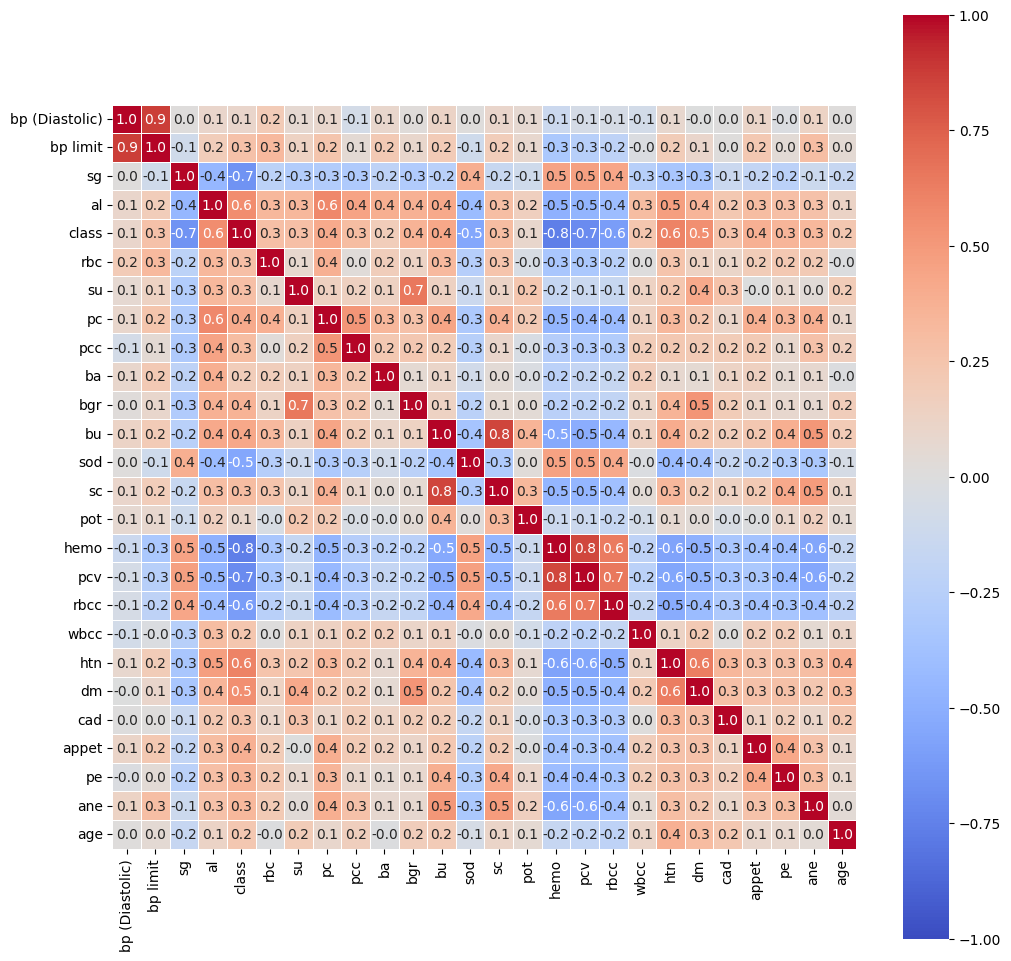

In [13]:
corr_x = X_check.drop(columns='const').corr()
plt.figure(figsize=(12, 12))
sns.heatmap(corr_x, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".1f", linewidths=0.5, square=True)

In [14]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

X_check2 = df.drop(columns=['stage', 'grf', 'bp limit', 'hemo', 'class']).select_dtypes(include='number')
X_check2 = add_constant(X_check2)  # VIF calc needs a constant term

vif_data2 = pd.DataFrame()
vif_data2['feature'] = X_check2.columns
vif_data2['VIF'] = [variance_inflation_factor(X_check2.values, i) for i in range(X_check2.shape[1])]
vif_data2 = vif_data2[vif_data2['feature'] != 'const'].sort_values('VIF', ascending=False)
print(vif_data2)

           feature       VIF
10              bu  4.795346
12              sc  4.158331
14             pcv  3.045946
6               pc  2.618784
3               al  2.496857
17             htn  2.449776
5               su  2.354622
9              bgr  2.336980
18              dm  2.302372
15            rbcc  2.104814
7              pcc  1.869439
22             ane  1.846039
2               sg  1.710029
11             sod  1.672845
13             pot  1.619344
21              pe  1.603724
4              rbc  1.511453
20           appet  1.484894
16            wbcc  1.391833
19             cad  1.388493
8               ba  1.350704
23             age  1.304470
1   bp (Diastolic)  1.139658


In [16]:
from statsmodels.miscmodels.ordinal_model import OrderedModel

y = df['stage']
X = X_check2.drop(columns='const')  # OrderedModel adds its own intercept-like thresholds, don't pass a constant

model = OrderedModel(y, X, distr='logit')
result = model.fit(method='bfgs', maxiter=5000, disp=False)
print(result.summary())

                             OrderedModel Results                             
Dep. Variable:                  stage   Log-Likelihood:                -151.80
Model:                   OrderedModel   AIC:                             357.6
Method:            Maximum Likelihood   BIC:                             446.5
Date:                Sat, 26 Sep 2026                                         
Time:                        10:01:22                                         
No. Observations:                 199                                         
Df Residuals:                     172                                         
Df Model:                          23                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
bp (Diastolic)     0.7044      0.336      2.097      0.036       0.046       1.363
sg                 0.0132      0.186    

In [17]:
results_df = pd.DataFrame({
    "coef": result.params,
    "std_err": result.bse,
    "p_value": result.pvalues
})
significant = results_df[results_df["p_value"] < 0.05]
print(significant)

                    coef   std_err       p_value
bp (Diastolic)  0.704440  0.335973  3.601907e-02
bu              2.402890  0.425832  1.673014e-08
sod            -0.593959  0.232295  1.056042e-02
pcv            -0.330829  0.149465  2.686897e-02
age             0.309383  0.092222  7.942992e-04
1/2             0.684278  0.156740  1.267307e-05
2/3             0.697876  0.165484  2.473619e-05


In [40]:
import sys
import subprocess

# This safely installs PyMC and Bambi into your exact active environment
subprocess.check_call([sys.executable, "-m", "pip", "install", "pymc", "bambi"])


import pymc as pm
import bambi as bmb
import pandas as pd
import arviz as az
import re

# 1. Create a clean dataframe
df_bayes = X.copy()
df_bayes['stage'] = pd.Categorical(y, ordered=True) # Required for cumulative family

# 2. CONVERT SODIUM TO DUMMY VARIABLES
# We use Group 2 as the baseline, so we only create columns for 1, 3, and 4
df_bayes['sod_group_1'] = (df_bayes['sod'] == 1).astype(int)
df_bayes['sod_group_3'] = (df_bayes['sod'] == 3).astype(int)
df_bayes['sod_group_4'] = (df_bayes['sod'] == 4).astype(int)

# Drop the original 'sod' column so the model doesn't get confused
df_bayes = df_bayes.drop(columns=['sod'])

# 3. AGGRESSIVELY CLEAN ALL COLUMN NAMES (Fixes 'bp (Diastolic)')
df_bayes.columns = [re.sub(r'[^a-zA-Z0-9_]', '_', col) for col in df_bayes.columns]

# 4. Build the formula dynamically
feature_cols = [col for col in df_bayes.columns if col != 'stage']
formula = "stage ~ " + " + ".join(feature_cols)

# 5. Define the flat, uninformative prior (Effect = 0)
flat_prior = bmb.Prior("Normal", mu=0, sigma=50)

# 6. Build the prior dictionary dynamically
custom_priors = {
    # Custom Informative Priors for Sodium Tiers (based on log HRs)
    "sod_group_1": bmb.Prior("Normal", mu=0.37, sigma=0.2), 
    "sod_group_3": bmb.Prior("Normal", mu=0.16, sigma=0.2),
    "sod_group_4": bmb.Prior("Normal", mu=0.20, sigma=0.2),
}

# Automatically assign the flat prior to every OTHER column
for col in feature_cols:
    if col not in custom_priors:
        custom_priors[col] = flat_prior

# 7. Initialize and Fit the model
model = bmb.Model(formula, data=df_bayes, family="cumulative")
model.set_priors(priors=custom_priors)
print("Sampling Bayesian Model...")
results = model.fit(draws=2000, chains=4, target_accept=0.9)

# 8. Get the 95% Credible Interval Summary
summary_df = az.summary(results, ci_prob=0.95)

# Dynamically find the new column names for the 95% bounds
lb_col = [col for col in summary_df.columns if '_lb' in col][0] 
ub_col = [col for col in summary_df.columns if '_ub' in col][0] 

# Filter for rows where the interval DOES NOT cross zero
significant_vars = summary_df[
    (summary_df[lb_col] > 0) | (summary_df[ub_col] < 0)
]

print(f"\n--- Variables with 95% Credible Intervals ({lb_col} to {ub_col}) that DO NOT cross zero ---")
display(significant_vars)

C:\Users\User7\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\bambi\formula.py:112: UserWarning: The intercept is omitted in ordinal families
  warnings.warn("The intercept is omitted in ordinal families")


Sampling Bayesian Model...


Initializing NUTS using jitter+adapt_diag...
C:\Users\User7\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pytensor\tensor\rewriting\elemwise.py:1004: UserWarning: Loop fusion failed because the resulting node would exceed the kernel argument limit.
  warn(
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [threshold, bp__Diastolic_, sg, al, rbc, su, pc, pcc, ba, bgr, bu, sc, pot, pcv, rbcc, wbcc, htn, dm, cad, appet, pe, ane, age, sod_group_1, sod_group_3, sod_group_4]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 234 seconds.
There were 17 divergences after tuning. Increase `target_accept` or reparameterize.



--- Variables with 95% Credible Intervals (eti95_lb to eti95_ub) that DO NOT cross zero ---


,mean,sd,eti95_lb,eti95_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
threshold[0],-3.09,0.54,-4.2,-2.1,5077,5016,1.00,0.0076,0.0058
threshold[1],-1.29,0.51,-2.3,-0.32,6249,5762,1.00,0.0064,0.0056
threshold[3],5.17,0.69,3.8,6.6,7820,6324,1.00,0.0078,0.0074
bu,1.963,0.342,1.3,2.7,5360,5294,1.00,0.0047,0.0037
sc,3.96,0.86,2.4,5.7,6024,5118,1.00,0.011,0.0096
pcv,-0.429,0.127,-0.69,-0.19,5229,5188,1.00,0.0018,0.0015
age,0.214,0.081,0.059,0.38,6028,5155,1.00,0.001,0.00094


In [41]:
# View the FULL table for just the sodium variables
full_summary = az.summary(results, ci_prob=0.95)
display(full_summary.loc[['sod_group_1', 'sod_group_3', 'sod_group_4']])

,mean,sd,eti95_lb,eti95_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
sod_group_1,0.341,0.19,-0.034,0.71,8307,6045,1.00,0.0021,0.0023
sod_group_3,0.081,0.176,-0.27,0.42,7658,6035,1.00,0.002,0.002
sod_group_4,0.02,0.188,-0.35,0.4,7754,5504,1.00,0.0021,0.0023
